# 🎮 Sesión 2: Extracción de Grafos (Caso Twitch)
De datos tabulares a topología de red.

## 🧠 Teoría Fundamental: De la Tabla a la Red
En el mundo real, los grafos rara vez vienen estructurados. Se **extraen** de bases de datos relacionales o logs transaccionales mediante ingeniería de datos.

### 1. El Grafo Bipartito
Es una red donde los nodos se dividen en dos conjuntos disjuntos (Ej. `Usuarios` y `Películas`, o `Clientes` y `Productos`). Las conexiones solo pueden existir **cruzando** de un conjunto a otro. Dos usuarios no pueden conectarse entre sí directamente.

### 2. Grafos de Co-ocurrencia (Colapsando la Red)
Para encontrar relaciones entre elementos del mismo conjunto (Ej. qué tan similares son dos usuarios, o qué productos se compran juntos), "colapsamos" el grafo bipartito. Si el *Usuario A* y el *Usuario B* vieron la misma película, creamos una arista directa entre ellos. El **peso** de la arista aumenta por cada iteración que compartan.

### 3. Centralidad de Grado (Degree Centrality)
Mide el poder topológico de un nodo basándose en la cantidad de conexiones proporcionales que tiene respecto al total de la red. Sirve para encontrar los "Hubs" o cuellos de botella.
$$ C_d(v) = \frac{deg(v)}{N - 1} $$

In [9]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

# 1. Cargar el Log
df = pd.read_csv('dataset/twitch_raids_y_collabs.csv')
display(df.head())

,Streamer_Origen,Streamer_Destino,Tipo_Interaccion
0,Rubius,Spreen,Raid
1,Rivers,AriGameplays,Co-op
2,Ibai,Spreen,Raid
3,Rivers,Spreen,Co-op
4,Ibai,Auronplay,Host


In [10]:
# 2. Extraer Pesos (Frecuencia de interacción)
interacciones = df.groupby(['Streamer_Origen', 'Streamer_Destino']).size().reset_index(name='Peso')
display(interacciones.head())

,Streamer_Origen,Streamer_Destino,Peso
0,AriGameplays,Auronplay,1
1,AriGameplays,ElMariana,2
2,AriGameplays,Ibai,2
3,AriGameplays,JuanSGuarnizo,4
4,AriGameplays,Quackity,1


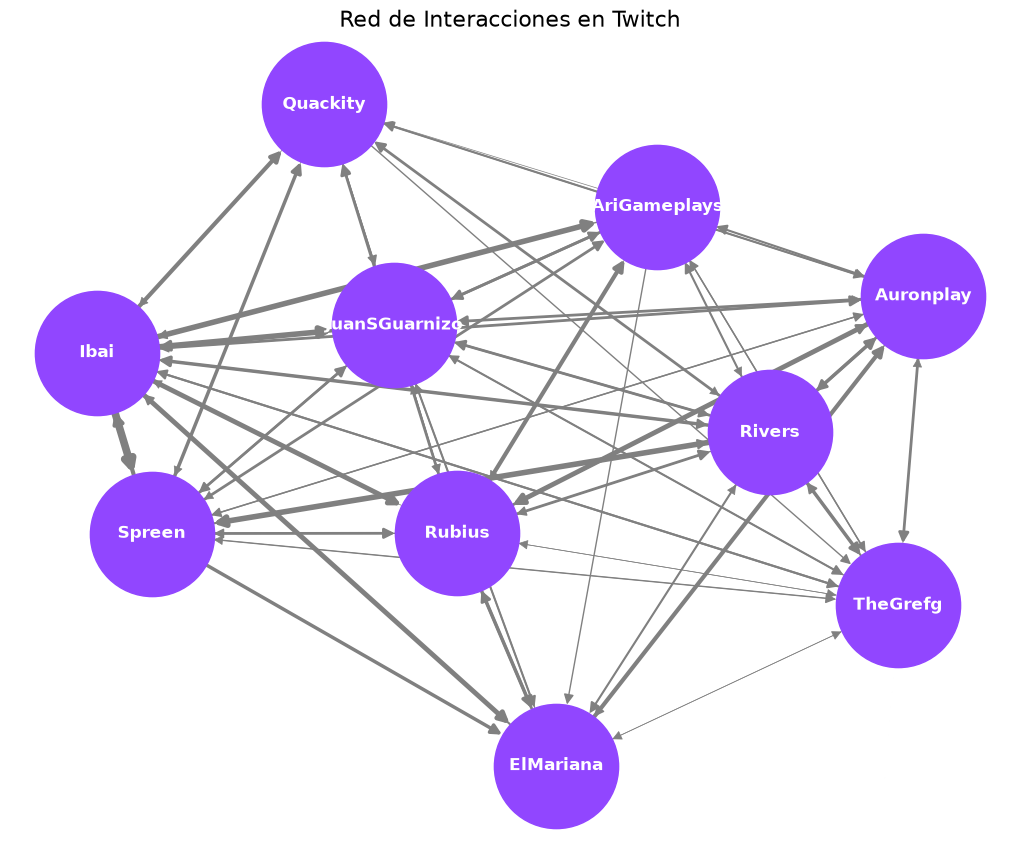

In [11]:
# 3. Construir Grafo desde Pandas
G_twitch = nx.from_pandas_edgelist(interacciones, source='Streamer_Origen', target='Streamer_Destino', edge_attr='Peso', create_using=nx.DiGraph())

# 4. Visualización con pesos
plt.figure(figsize=(10,8))
pos = nx.spring_layout(G_twitch, seed=42)
pesos = [d['Peso']*0.5 for (u, v, d) in G_twitch.edges(data=True)]
nx.draw(G_twitch, pos, with_labels=True, node_color='#9146FF', node_size=8000, font_color='white', font_weight='bold', width=pesos, edge_color='gray', arrowsize=15)
plt.title('Red de Interacciones en Twitch', fontsize=16)
plt.show()

In [12]:
# Calcula qué porcentaje de la red está conectado a cada streamer
nx.degree_centrality(G_twitch)

{'AriGameplays': 1.7777777777777777,
 'Auronplay': 2.0,
 'ElMariana': 1.5555555555555554,
 'Ibai': 2.0,
 'JuanSGuarnizo': 2.0,
 'Quackity': 1.5555555555555554,
 'Rivers': 2.0,
 'Rubius': 2.0,
 'Spreen': 1.8888888888888888,
 'TheGrefg': 1.8888888888888888}